# Finite differences and spatial truncation error

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §5.1–5.2, pp. 37–41.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

Taylor expansions at neighbouring points yield forward difference (f(x+h)-f(x))/h with O(h) error and central difference (f(x+h)-f(x-h))/(2h) with O(h²) error. The central second derivative is (f(x+h)-2f(x)+f(x-h))/h², also O(h²) for a sufficiently smooth function.

A PDE discretisation must specify both boundary and initial conditions. Periodic indexing is appropriate for periodic problems only. Dirichlet boundaries prescribe values; Neumann boundaries prescribe normal derivatives or fluxes. The method of lines discretises space first, producing a system of ODEs in time.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

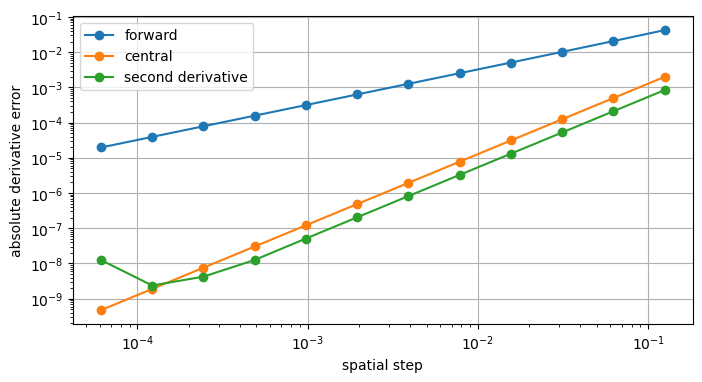

In [2]:
hs=2.**-np.arange(3,15);x=.7
forward=(np.sin(x+hs)-np.sin(x))/hs
central=(np.sin(x+hs)-np.sin(x-hs))/(2*hs)
second=(np.sin(x+hs)-2*np.sin(x)+np.sin(x-hs))/hs**2
for label,err in [("forward",abs(forward-np.cos(x))),("central",abs(central-np.cos(x))),("second derivative",abs(second+np.sin(x)))]:
 plt.loglog(hs,err,"o-",label=label)
plt.xlabel("spatial step");plt.ylabel("absolute derivative error");plt.legend();plt.show()
assert abs(central[5]-np.cos(x))<abs(forward[5]-np.cos(x))

## Read the result

Refining space reduces truncation error until subtraction and division amplify roundoff. The second derivative is particularly sensitive because it divides by h².

## Your turn

Derive the leading error term for each stencil. Explain why testing at x=0 would be a misleading comparison for sin(x).

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.